# All Models Comparison

**Review 2 - Consolidated comparison of all ten classifiers**

The five Part A baselines and five Part B classifiers use the same dataset, split, features and
fold-safe preprocessing. Model selection uses five-fold training macro F1 only; held-out metrics
describe final performance and never choose the winner.

## 1. Imports

In [1]:
from pathlib import Path
import json
import os
import sys
import warnings

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if not (ROOT / "src").exists():
    raise RuntimeError("Open this notebook inside the project or project/notebooks folder.")
sys.path.insert(0, str(ROOT))

from threadpoolctl import threadpool_limits

thread_limit = threadpool_limits(limits=1)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

%matplotlib inline
sns.set_theme(style="whitegrid", palette="colorblind")
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    classification_report,
)
from sklearn.model_selection import GridSearchCV, cross_validate
import joblib

from src.classification import *


## 2. Dataset audit and comparison scope

In [2]:
raw, df, train, test = load_data()
X_train, y_train = train[RAW_FEATURES], train[TARGET]
X_test, y_test = test[RAW_FEATURES], test[TARGET]

display(
    pd.DataFrame(
        {
            "Raw": raw[TARGET].value_counts(),
            "Cleaned": df[TARGET].value_counts(),
            "Train": y_train.value_counts(),
            "Test": y_test.value_counts(),
        }
    )
)
display(df.dtypes.to_frame("dtype").astype(str))
print("Raw shape:", raw.shape)
print("Cleaned shape:", df.shape)
print("Removed exact duplicate rows:", len(raw) - len(df))
print("Training rows:", len(train), "| Held-out test rows:", len(test))
assert not df.duplicated().any()
assert set(train.index).isdisjoint(test.index)

expected_models = pd.DataFrame(
    [
        {"Slug": slug, "Model": name, "Part": "A"}
        for slug, (name, _) in part_a_models().items()
    ]
    + [
        {"Slug": slug, "Model": values[0], "Part": "B"}
        for slug, values in configurations().items()
    ]
)
display(expected_models)
assert len(expected_models) == 10


Raw shape: (2500, 10)
Cleaned shape: (2500, 10)
Removed exact duplicate rows: 0
Training rows: 2000 | Held-out test rows: 500


,Raw,Cleaned,Train,Test
transmission,,,,
Automatic,1250,1250,1000,250
Manual,1250,1250,1000,250


,dtype
brand,object
model,object
year,int64
price_gbp,int64
mileage_miles,int64
fuel_type,object
tax_gbp,int64
mpg_uk,float64
engine_size_l,float64
transmission,string


,Slug,Model,Part
0,logistic_regression,Logistic Regression,A
1,knn,KNN,A
2,naive_bayes,Gaussian Naive Bayes,A
3,decision_tree,Decision Tree,A
4,svc,SVC,A
5,random_forest,Random Forest,B
6,adaboost,AdaBoost,B
7,gradient_boosting,Gradient Boosting,B
8,bagging,Bagging,B
9,mlp,MLP,B


## 3. Required result audit

In [3]:
part_a_tables = []
for slug in part_a_models():
    path = ROOT / "results" / slug / "comparison.csv"
    if not path.exists():
        raise FileNotFoundError(f"Run the {slug} notebook first: {path}")
    table = pd.read_csv(path)
    part_a_tables.append(table)
part_a = pd.concat(part_a_tables, ignore_index=True)
part_a.to_csv(ROOT / "results" / "part_a_rerun.csv", index=False)

part_b_tables = []
for slug in configurations():
    path = ROOT / "results" / slug / "comparison.csv"
    if not path.exists():
        raise FileNotFoundError(f"Run the {slug} notebook first: {path}")
    table = pd.read_csv(path)
    table["Slug"] = slug
    table["Part"] = "B"
    part_b_tables.append(table)
part_b = pd.concat(part_b_tables, ignore_index=True)

display(part_a[["Model", "Stage", "CV_macro_F1", "F1_macro"]].round(4))
display(
    part_b[["Model", "Stage", "CV_macro_F1", "F1_macro"]]
    .sort_values(["Model", "Stage"])
    .round(4)
)
assert part_a["Slug"].nunique() == 5
assert part_b["Slug"].nunique() == 5

,Model,Stage,CV_macro_F1,F1_macro
0,Logistic Regression,Baseline,0.8358,0.8275
1,KNN,Baseline,0.8264,0.8178
2,Gaussian Naive Bayes,Baseline,0.6770,0.6339
3,Decision Tree,Baseline,0.8090,0.8279
4,SVC,Baseline,0.8298,0.8356


,Model,Stage,CV_macro_F1,F1_macro
3,AdaBoost,After tuning,0.8099,0.8049
2,AdaBoost,Before tuning,0.8052,0.8138
7,Bagging,After tuning,0.8489,0.8620
6,Bagging,Before tuning,0.8354,0.8420
5,Gradient Boosting,After tuning,0.8373,0.8577
4,Gradient Boosting,Before tuning,0.8319,0.8577
9,MLP,After tuning,0.8449,0.8459
8,MLP,Before tuning,0.8449,0.8459
1,Random Forest,After tuning,0.8550,0.8679
0,Random Forest,Before tuning,0.8550,0.8679


## 4. Model result consolidation

In [4]:
all_runs = pd.concat([part_a, part_b], ignore_index=True)
all_runs.to_csv(ROOT / "results" / "all_classification_runs.csv", index=False)
part_b.to_csv(ROOT / "results" / "part_b_before_after.csv", index=False)

after = part_b[part_b.Stage == "After tuning"].sort_values(
    "CV_macro_F1", ascending=False
)
after.to_csv(ROOT / "results" / "after_tuning_comparison.csv", index=False)
print("All five Part B models after tuning, ordered by training CV macro F1:")
display(after.round(4))

All five Part B models after tuning, ordered by training CV macro F1:


,Model,Stage,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,Balanced_accuracy,Automatic_precision,Automatic_recall,ROC_AUC,Average_precision_Automatic,CV_macro_F1,CV_macro_F1_std,Slug,Part
1,Random Forest,After tuning,0.868,0.8692,0.868,0.8679,0.8679,0.868,0.8898,0.840,0.9347,0.9403,0.8550,0.0147,random_forest,B
7,Bagging,After tuning,0.862,0.8625,0.862,0.8620,0.8620,0.862,0.8755,0.844,0.9336,0.9344,0.8489,0.0258,bagging,B
9,MLP,After tuning,0.846,0.8469,0.846,0.8459,0.8459,0.846,0.8650,0.820,0.9273,0.9344,0.8449,0.0180,mlp,B
5,Gradient Boosting,After tuning,0.858,0.8605,0.858,0.8577,0.8577,0.858,0.8908,0.816,0.9267,0.9353,0.8373,0.0203,gradient_boosting,B
3,AdaBoost,After tuning,0.806,0.8129,0.806,0.8049,0.8049,0.806,0.8592,0.732,0.9005,0.9048,0.8099,0.0257,adaboost,B


In [5]:
delta_rows = []
for slug, group in part_b.groupby("Slug", sort=False):
    before = group[group.Stage == "Before tuning"].iloc[0]
    tuned_row = group[group.Stage == "After tuning"].iloc[0]
    columns = [
        "Accuracy",
        "Precision_weighted",
        "Recall_weighted",
        "F1_weighted",
        "F1_macro",
        "ROC_AUC",
        "CV_macro_F1",
    ]
    delta_rows.append(
        {
            "Model": before.Model,
            **{column: float(tuned_row[column] - before[column]) for column in columns},
        }
    )
deltas = pd.DataFrame(delta_rows)
deltas.to_csv(ROOT / "results" / "tuning_deltas.csv", index=False)
print("After minus before:")
display(deltas.round(4))

After minus before:


,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,ROC_AUC,CV_macro_F1
0,Random Forest,0.000,0.0000,0.000,0.0000,0.0000,0.0000,0.0000
1,AdaBoost,-0.008,-0.0026,-0.008,-0.0089,-0.0089,0.0027,0.0047
2,Gradient Boosting,0.000,-0.0005,0.000,0.0001,0.0001,-0.0030,0.0055
3,Bagging,0.020,0.0204,0.020,0.0200,0.0200,0.0169,0.0135
4,MLP,0.000,0.0000,0.000,0.0000,0.0000,0.0000,0.0000


## 5. Evaluation and final model selection

In [6]:
ranked_runs = all_runs.assign(
    _stage_priority=all_runs["Stage"].eq("After tuning").astype(int)
)
selected = (
    ranked_runs.sort_values(
        ["CV_macro_F1", "_stage_priority"],
        ascending=[False, False],
        kind="stable",
    )
    .drop_duplicates("Slug")
    .drop(columns="_stage_priority")
    .reset_index(drop=True)
)
selected.to_csv(ROOT / "results" / "ten_model_comparison.csv", index=False)
display(selected.round(4))

winner = selected.iloc[0]
suffix = "after" if winner.Stage == "After tuning" else "before"
selection = {
    "slug": winner.Slug,
    "name": winner.Model,
    "stage": winner.Stage,
    "model_file": f"{winner.Slug}_{suffix}.joblib",
    "cv_macro_f1": float(winner.CV_macro_F1),
    "selection_basis": "Highest five-fold training CV macro F1; exact ties prefer the CV-selected after-tuning variant; test metrics not used",
}
(ROOT / "results" / "selected_model.json").write_text(
    json.dumps(selection, indent=2), encoding="utf-8"
)
print("Final model selection:", selection)

Final model selection: {'slug': 'random_forest', 'name': 'Random Forest', 'stage': 'After tuning', 'model_file': 'random_forest_after.joblib', 'cv_macro_f1': 0.8549557420459012, 'selection_basis': 'Highest five-fold training CV macro F1; exact ties prefer the CV-selected after-tuning variant; test metrics not used'}


,Slug,Model,Part,Stage,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,Balanced_accuracy,Automatic_precision,Automatic_recall,ROC_AUC,Average_precision_Automatic,CV_macro_F1,CV_macro_F1_std
0,random_forest,Random Forest,B,After tuning,0.868,0.8692,0.868,0.8679,0.8679,0.868,0.8898,0.840,0.9347,0.9403,0.8550,0.0147
1,bagging,Bagging,B,After tuning,0.862,0.8625,0.862,0.8620,0.8620,0.862,0.8755,0.844,0.9336,0.9344,0.8489,0.0258
2,mlp,MLP,B,After tuning,0.846,0.8469,0.846,0.8459,0.8459,0.846,0.8650,0.820,0.9273,0.9344,0.8449,0.0180
3,gradient_boosting,Gradient Boosting,B,After tuning,0.858,0.8605,0.858,0.8577,0.8577,0.858,0.8908,0.816,0.9267,0.9353,0.8373,0.0203
4,logistic_regression,Logistic Regression,A rerun,Baseline,0.828,0.8322,0.828,0.8275,0.8275,0.828,0.8694,0.772,0.9227,0.9298,0.8358,0.0185
5,svc,SVC,A rerun,Baseline,0.836,0.8391,0.836,0.8356,0.8356,0.836,0.8717,0.788,0.9229,0.9328,0.8298,0.0211
6,knn,KNN,A rerun,Baseline,0.818,0.8195,0.818,0.8178,0.8178,0.818,0.8412,0.784,0.8924,0.8768,0.8264,0.0210
7,adaboost,AdaBoost,B,After tuning,0.806,0.8129,0.806,0.8049,0.8049,0.806,0.8592,0.732,0.9005,0.9048,0.8099,0.0257
8,decision_tree,Decision Tree,A rerun,Baseline,0.828,0.8285,0.828,0.8279,0.8279,0.828,0.8417,0.808,0.8280,0.7761,0.8090,0.0136
9,naive_bayes,Gaussian Naive Bayes,A rerun,Baseline,0.670,0.7807,0.670,0.6339,0.6339,0.670,0.9570,0.356,0.8449,0.8569,0.6770,0.0206


## 6. Comparison visualizations and model interpretation

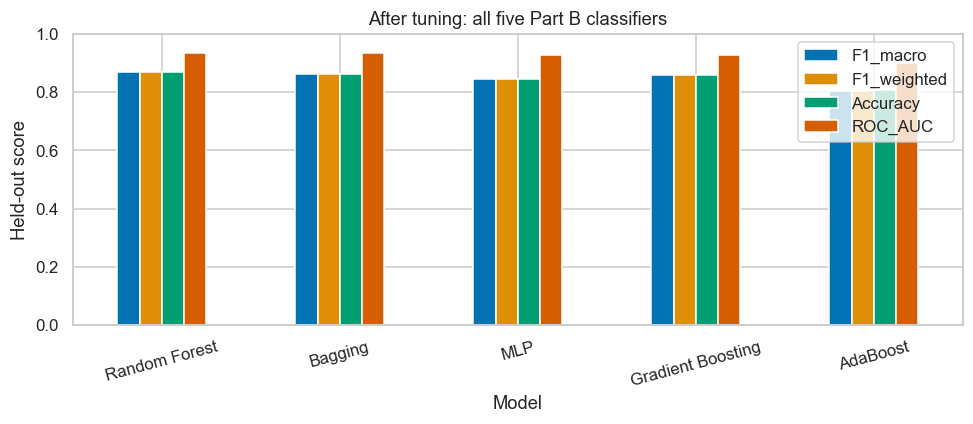

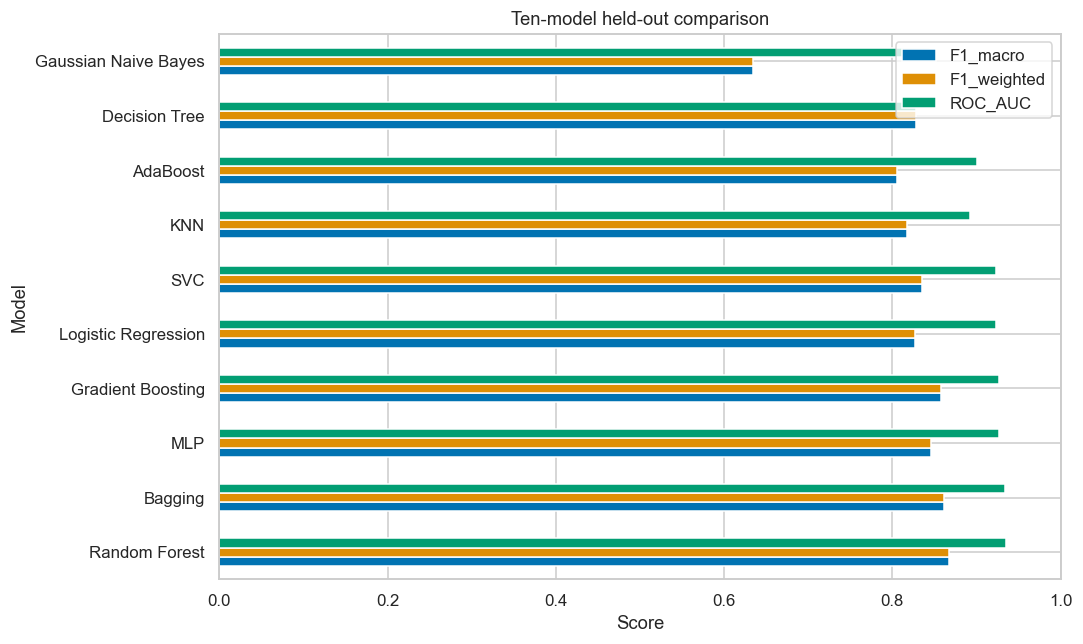

In [7]:
fig, axis = plt.subplots(figsize=(9, 4))
after.set_index("Model")[["F1_macro", "F1_weighted", "Accuracy", "ROC_AUC"]].plot.bar(
    ax=axis, ylim=(0, 1)
)
axis.set(
    title="After tuning: all five Part B classifiers",
    ylabel="Held-out score",
    xlabel="Model",
)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(ROOT / "results" / "after_tuning_comparison.png", dpi=130)
plt.show()

axis = selected.set_index("Model")[["F1_macro", "F1_weighted", "ROC_AUC"]].plot.barh(
    figsize=(10, 6), xlim=(0, 1)
)
axis.set(title="Ten-model held-out comparison", xlabel="Score", ylabel="Model")
plt.tight_layout()
plt.savefig(ROOT / "results" / "ten_model_comparison.png", dpi=130)
plt.show()

## 7. Observation / Interpretation

Complete the review discussion using the tables and plots above:

- Explain why the selected model wins according to training CV macro F1.
- Compare its held-out performance with the strongest alternatives.
- Discuss the Automatic-class precision/recall tradeoff.
- Report any metric that did not improve after tuning instead of changing the split.
- Explain why the common split and preprocessing are necessary for a fair ten-model comparison.

The original Review 1 scores are not mixed into this table; all ten values are comparable reruns.